# 01 Sections 3 4 Three Minute Script

Archives the presentation script for the forecasting-method and RQ1 sections.

**Provenance.** This is an English-facing execution copy of the original project notebook. The computational cells are preserved so that the analysis remains reproducible. Chinese narrative cells have been replaced by concise English stage notes; the original notebook remains unchanged in the source project.

## Analysis stage 1

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from IPython.display import Image, display

PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data' / 'processed').exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the final_submission project root.')
RQ1_EN = PROJECT_ROOT / 'output' / 'rq1' / 'en'
RQ1_ZH = PROJECT_ROOT / 'output' / 'rq1' / 'zh'
CHAMPION_CSV = RQ1_ZH / 'champion_models_balanced_ranking.csv'
required = [RQ1_EN / 'rq1_six_model_comparison.png', CHAMPION_CSV]
missing = [str(p) for p in required if not p.exists()]
assert not missing, f'Missing required files: {missing}'
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})
champions = pd.read_csv(CHAMPION_CSV)
champions = champions[champions['model'].isin(['Optimised FNN', 'Optimised KNN', 'Optimised Random Forest'])].reset_index(drop=True)
print('Loaded', len(champions), 'finalist models')

Matplotlib is building the font cache; this may take a moment.


Loaded 3 finalist models


## Analysis stage 2

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

## Analysis stage 3

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

## Analysis stage 4

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

In [2]:
fig, ax = plt.subplots(figsize=(15, 5.4))
ax.set_xlim(0, 15); ax.set_ylim(0, 6); ax.axis('off')
stages = [
    (0.2, 1.2, 3.1, 3.6, 'INITIAL COMPARISON', 'Two physical baselines\nVAR(1), Ridge, KNN, FNN', '#e0f2fe'),
    (3.8, 1.2, 3.1, 3.6, 'EARLY LEADERS', 'FNN\nWeighted KNN', '#ede9fe'),
    (7.4, 1.2, 3.1, 3.6, 'TREE EXTENSION', 'Extra Trees\nRandom Forest', '#fef3c7'),
    (11.0, 1.2, 3.7, 3.6, 'OPTIMISED FINALISTS', 'Optimised FNN\nOptimised KNN\nOptimised Random Forest', '#dcfce7')
]
for x,y,w,h,title,body,color in stages:
    ax.add_patch(FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.12',facecolor=color,edgecolor='#1f4e79',linewidth=2))
    ax.text(x+w/2,y+h-0.55,title,ha='center',va='center',fontsize=15,fontweight='bold',color='#12324a')
    ax.text(x+w/2,y+1.55,body,ha='center',va='center',fontsize=12.5,linespacing=1.45,color='#243b53')
for x1,x2 in [(3.3,3.75),(6.9,7.35),(10.5,10.95)]:
    ax.add_patch(FancyArrowPatch((x1,3),(x2,3),arrowstyle='-|>',mutation_scale=22,linewidth=2,color='#1f4e79'))
ax.text(7.5,5.55,'Model selection progressed from broad comparison to focused optimisation',ha='center',fontsize=18,fontweight='bold')
ax.text(7.5,0.45,'All three finalists used the same 98-dimensional input and drifter-grouped cross-validation.',ha='center',fontsize=11.5,color='#4b5563')
plt.show()

/var/folders/1c/wbxz8krj5nn0086j5f4mk5hc0000gn/T/ipykernel_83039/114101503.py:17: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Analysis stage 5

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

## Analysis stage 6

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

## Analysis stage 7

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

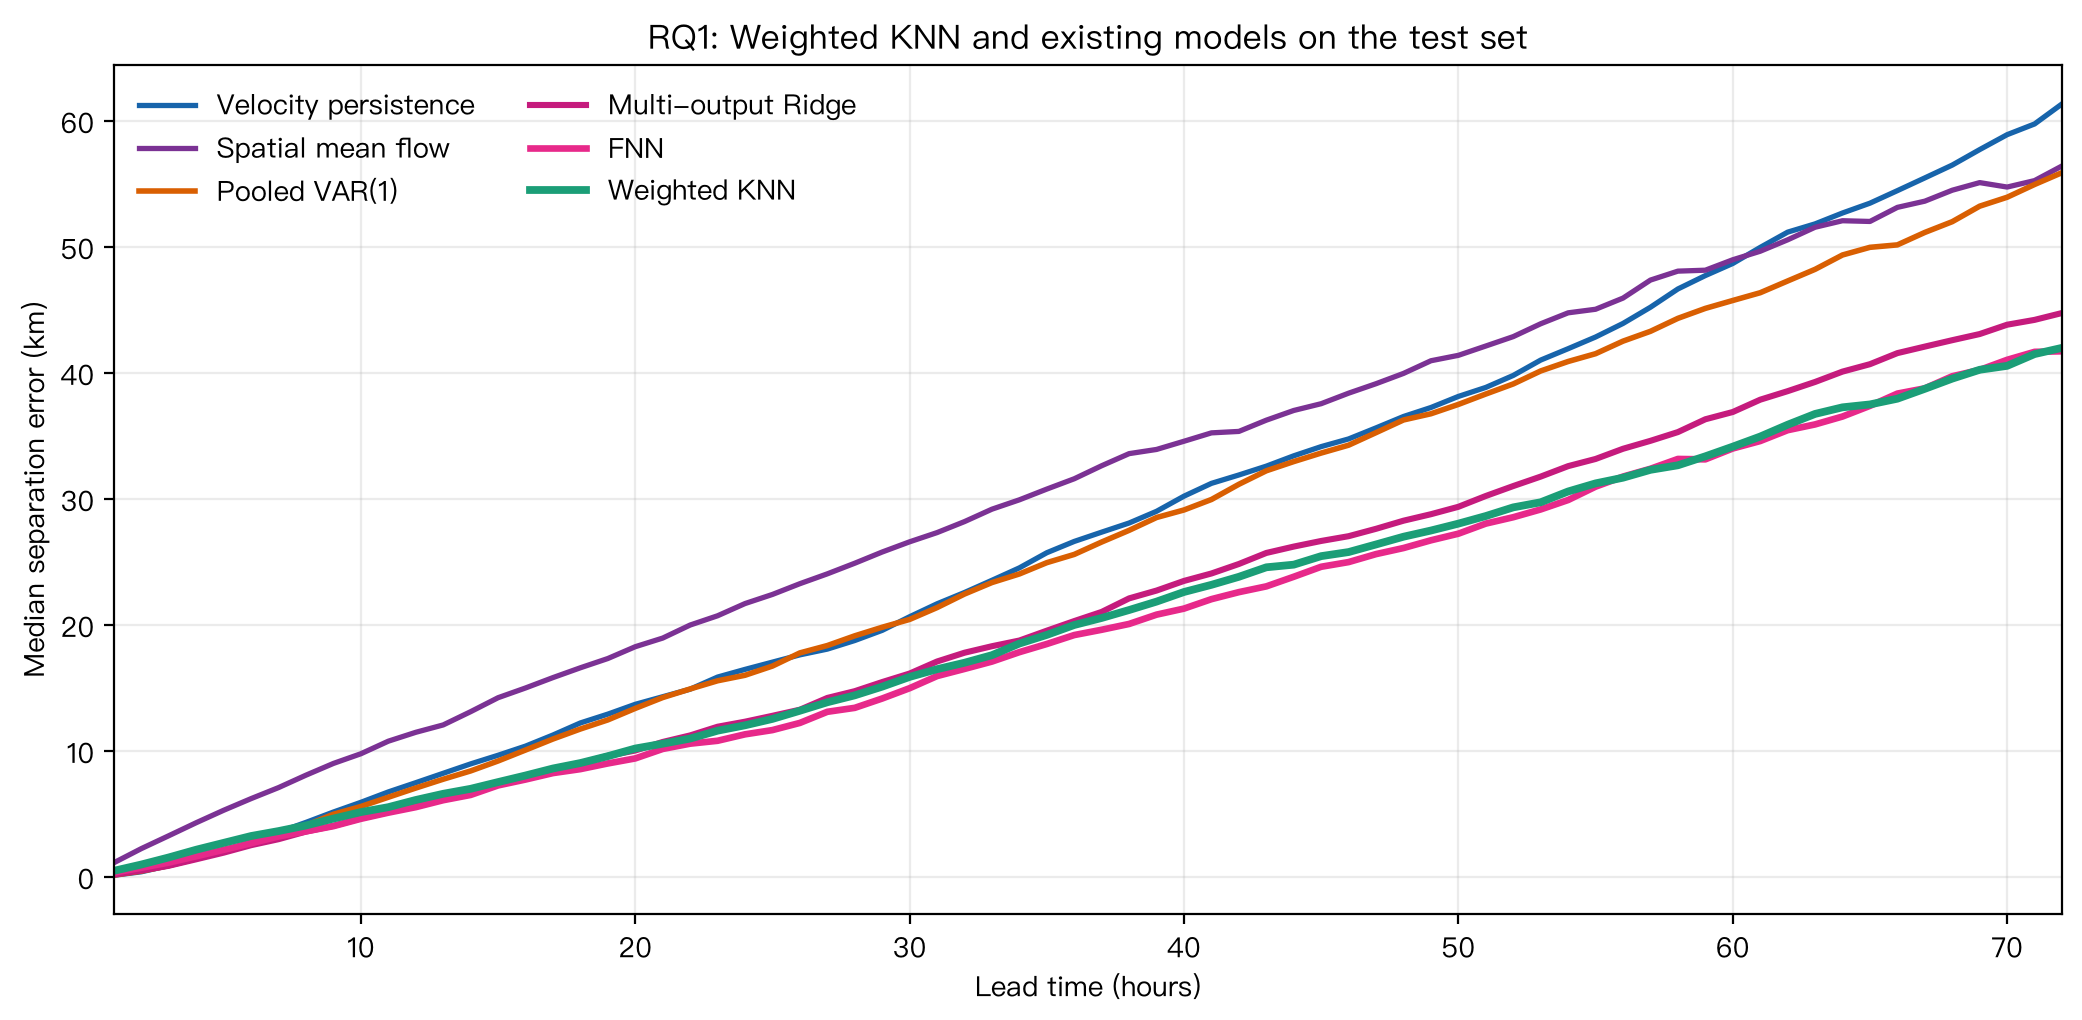

In [3]:
display(Image(filename=str(RQ1_EN / 'rq1_six_model_comparison.png'), width=1050))

## Analysis stage 8

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

In [4]:
plot_specs = [
    ('median_72h_km', 'Median 72-h endpoint error', 'km'),
    ('rmse_72h_km', '72-h endpoint RMSE', 'km'),
    ('median_ite_km_h', 'Median 72-h integrated trajectory error', 'km·h'),
    ('worst10_rmse_72h_km', 'Worst-10% endpoint RMSE', 'km')
]
palette = {'Optimised FNN':'#db2777','Optimised Random Forest':'#2563eb','Optimised KNN':'#059669'}
fig, axes = plt.subplots(2, 2, figsize=(14, 8.8))
for ax, (col, title, unit) in zip(axes.flat, plot_specs):
    d = champions.sort_values(col, ascending=True)
    y = np.arange(len(d))
    ax.hlines(y, 0, d[col], color='#d1d5db', linewidth=4)
    ax.scatter(d[col], y, s=120, color=[palette[m] for m in d['model']], zorder=3)
    ax.set_yticks(y, d['model']); ax.invert_yaxis()
    ax.set_title(title, fontweight='bold'); ax.set_xlabel(unit); ax.set_xlim(left=0)
    for yi, val in zip(y, d[col]): ax.text(val, yi, f'  {val:.2f}', va='center', fontsize=10)
fig.suptitle('Three optimised finalists: complementary strengths', fontsize=18, fontweight='bold', y=1.01)
fig.tight_layout(); plt.show()
display(champions[['model','median_72h_km','rmse_72h_km','median_ite_km_h','worst10_rmse_72h_km','balanced_rank']].round(2))

/var/folders/1c/wbxz8krj5nn0086j5f4mk5hc0000gn/T/ipykernel_83039/2613271364.py:18: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.tight_layout(); plt.show()


,model,median_72h_km,rmse_72h_km,median_ite_km_h,worst10_rmse_72h_km,balanced_rank
0,Optimised FNN,41.34,61.69,1403.16,134.60,1.75
1,Optimised Random Forest,41.89,62.17,1414.58,136.60,3.00
2,Optimised KNN,41.13,63.71,1433.11,142.08,3.25


## Analysis stage 9

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

## Complete 3-minute English script

**Slide 1 — RQ1**  
For RQ1, we asked how trajectory error grows with forecast lead time and which approach performs best on held-out drifters.

**Slide 2 — Model development**  
We used a staged model-development process. We first compared two physical baselines with four learned models: VAR, Ridge, weighted KNN and FNN. FNN and weighted KNN were the strongest initial models. We then tested Extra Trees and Random Forest, and found that Random Forest was also competitive. We therefore focused the final tuning on FNN, KNN and Random Forest.

**Slide 3 — Evaluation**  
Each case used 24 hours of observations to predict the next 72 hours. We split data by drifter, selected hyperparameters using grouped five-fold cross-validation on the training partition, reserved calibration for uncertainty analysis, and used 757 test cases only for the final evaluation. We assessed median error, RMSE, integrated trajectory error and the worst ten percent of cases.

**Slide 4 — Initial benchmark**  
In the initial benchmark, error increased steadily with lead time. The learned models, especially FNN and weighted KNN, increasingly outperformed the physical baselines at longer horizons. This motivated the second-stage model search.

**Slide 5 — Finalists**  
The final comparison shows complementary strengths. Optimised KNN gives the lowest median endpoint error. Optimised FNN gives the lowest endpoint RMSE and the best integrated trajectory error among the three CV-selected finalists. The complete comparison also shows that the original Random Forest has a slightly lower median integrated error, so these small differences should not be overstated.

**Slide 6 — Selection**  
Therefore, we selected optimised FNN as the primary forecasting model because it provides the strongest overall balance, while optimised KNN remains useful when typical-case median error is the priority and Random Forest remains competitive for integrated trajectory error. The result is not simply that a more complex model is always better; the model class and evaluation objective both matter.

## Analysis stage 10

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

## Analysis stage 11

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.

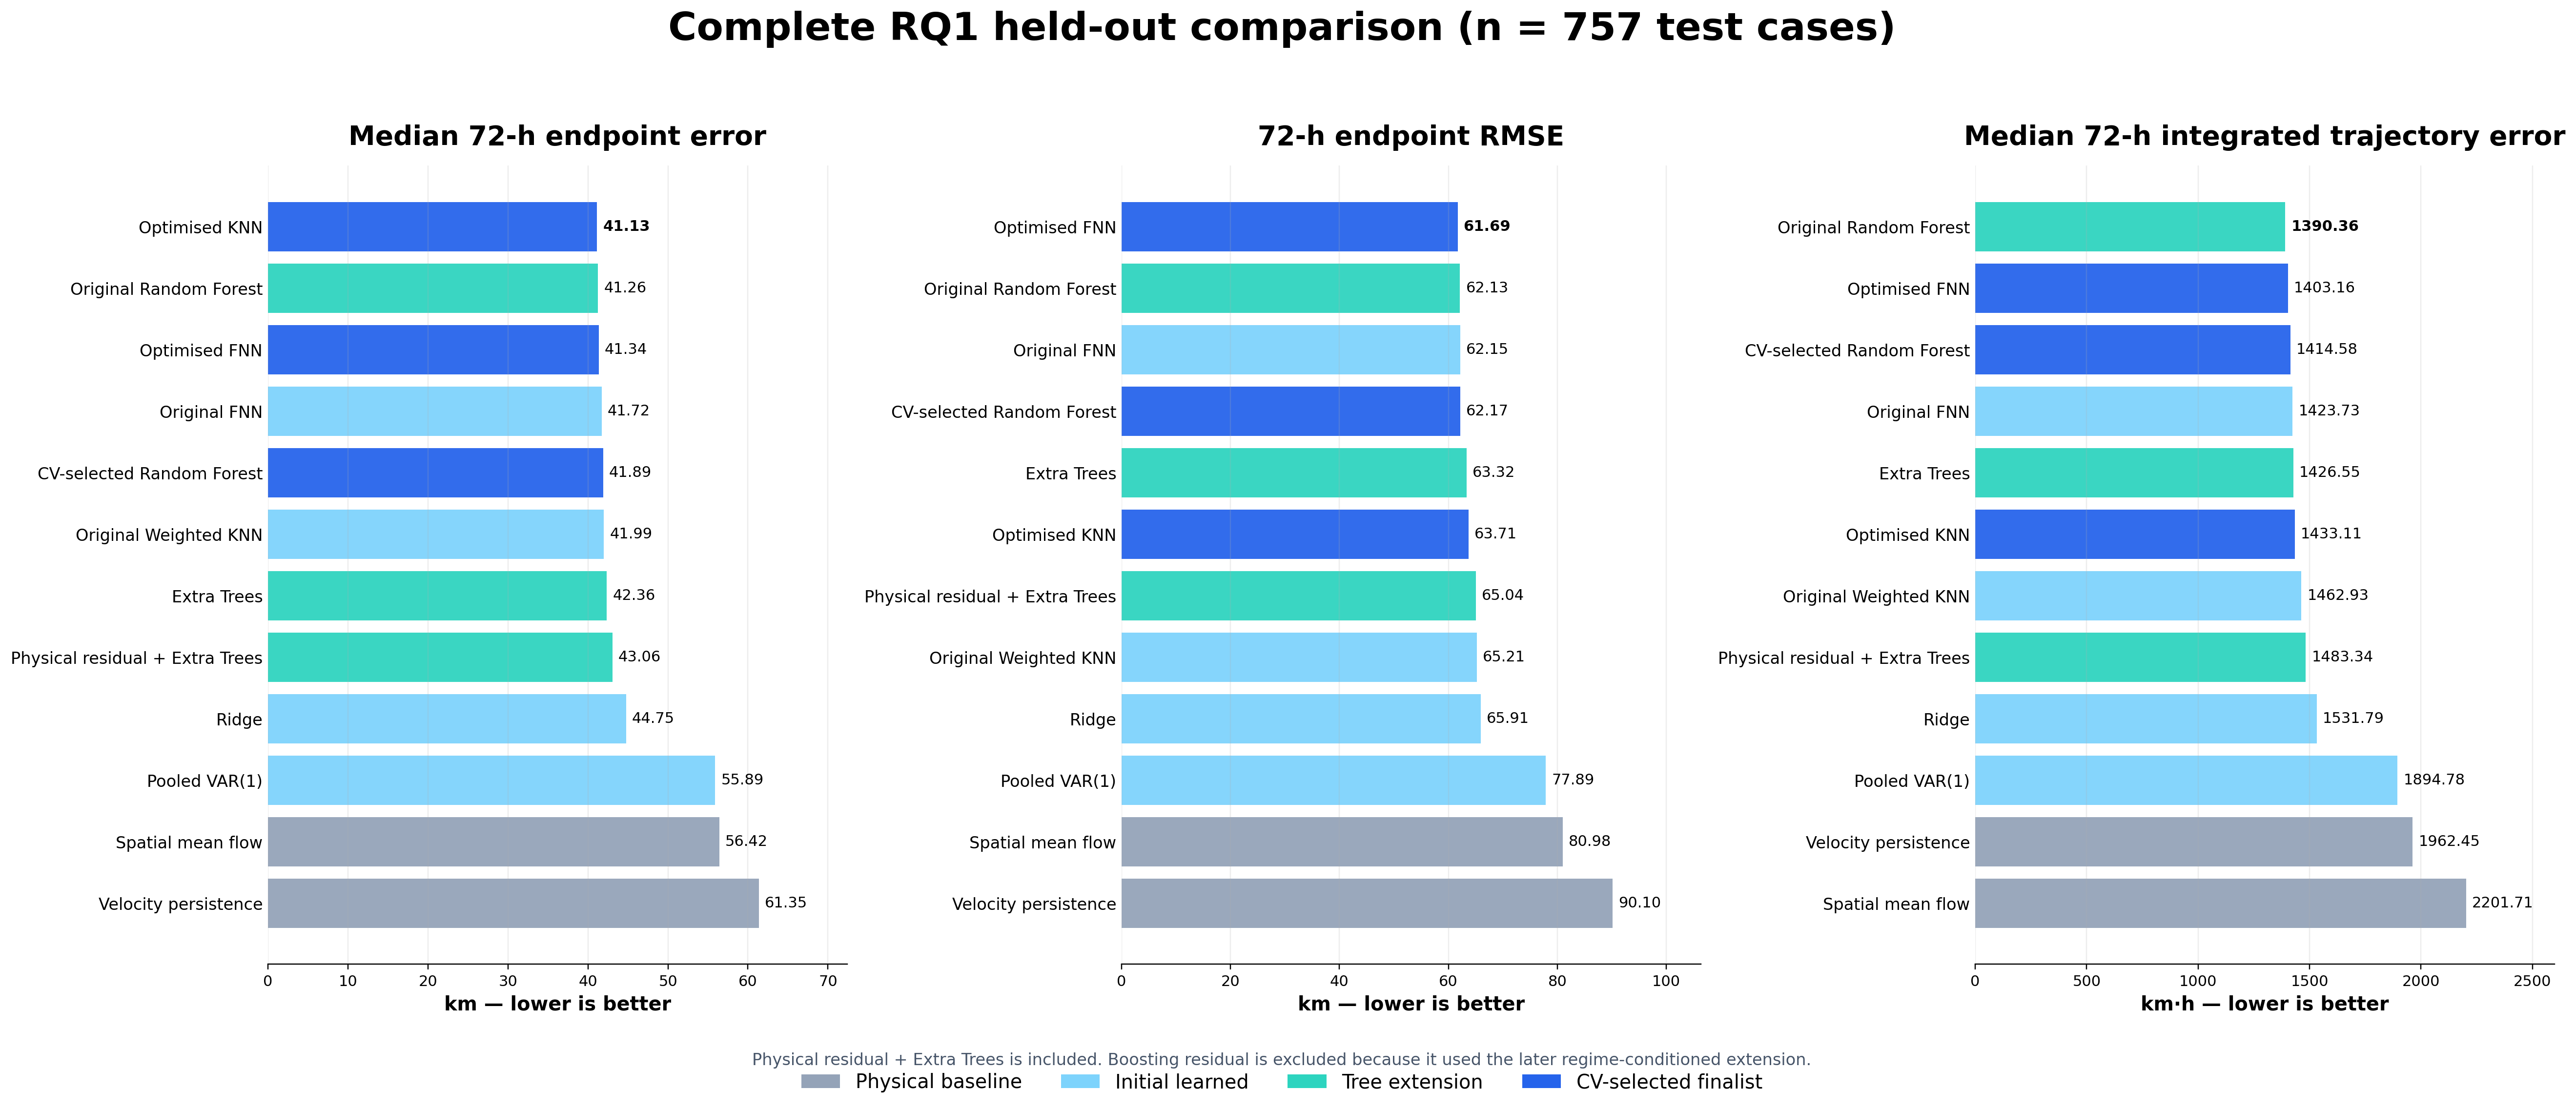

,model,median_72h_km,rmse_72h_km,median_ite_km_h
11,Optimised FNN,41.34,61.69,1403.16
8,Original Random Forest,41.26,62.13,1390.36
5,Original FNN,41.72,62.15,1423.73
10,CV-selected Random Forest,41.89,62.17,1414.58
6,Extra Trees,42.36,63.32,1426.55
9,Optimised KNN,41.13,63.71,1433.11
7,Physical residual + Extra Trees,43.06,65.04,1483.34
4,Original Weighted KNN,41.99,65.21,1462.93
3,Ridge,44.75,65.91,1531.79
2,Pooled VAR(1),55.89,77.89,1894.78


In [5]:
complete_csv = RQ1_ZH / 'complete_rq1_heldout_comparison_with_ite.csv'
complete_png = RQ1_ZH / 'complete_rq1_heldout_comparison_with_ite.png'
assert complete_csv.exists() and complete_png.exists()
complete_models = pd.read_csv(complete_csv)
display(Image(filename=str(complete_png), width=1500))
display(complete_models.sort_values('rmse_72h_km')[['model','median_72h_km','rmse_72h_km','median_ite_km_h']].round(2))

## Analysis stage 12

This stage documents the next part of the analysis. The following code and retained outputs provide the exact computational record.